In [1]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
import io
from torchvision import transforms, models
from torch.utils.data import Dataset, DataLoader
import ipywidgets as widgets
from IPython.display import display, clear_output
import json
import torch.nn.functional as F
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.metrics import balanced_accuracy_score, classification_report, confusion_matrix



In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
with open("label_map.json") as f:
    label_map = json.load(f)

idx_to_label = {v: k for k, v in label_map.items()}
class_names = list(label_map.keys())

label_explanations = {
    "Herniated Disc": "Disc material is displaced, possibly compressing nerves.",
    "No Stenosis": "Normal spinal canal with no narrowing detected.",
    "Thecal Sac": "Possible compression or narrowing around the thecal sac."
}

In [4]:
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

In [5]:
class MRIDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row["image_path"]).convert("L")
        label = label_map[row["label"]]

        if self.transform:
            image = self.transform(image)

        return image, label

In [6]:
val_df = pd.read_csv("val_split.csv")

val_dataset = MRIDataset(val_df, transform=transform)
val_loader = DataLoader(val_dataset, batch_size=32)

In [7]:
class SimpleCNN(nn.Module):

    def __init__(self):
        super(SimpleCNN, self).__init__()

        self.block1 = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2,2)
        )

        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2,2)
        )

        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2,2)
        )

        self.block4 = nn.Sequential(
            nn.Conv2d(128, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2,2)
        )

        self.global_pool = nn.AdaptiveAvgPool2d((1,1))

        self.fc1 = nn.Linear(256, 128)
        self.fc2 = nn.Linear(128, 3)

        self.dropout = nn.Dropout(0.4)

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)

        x = self.global_pool(x)
        x = torch.flatten(x, 1)

        x = self.dropout(F.relu(self.fc1(x)))
        x = self.fc2(x)
        return x

In [8]:
def build_resnet18():
    model = models.resnet18(weights=None)
    model.conv1 = nn.Conv2d(1, 64, 7, stride=2, padding=3, bias=False)
    model.fc = nn.Linear(model.fc.in_features, 3)
    return model

In [9]:
def build_efficientnet():
    model = models.efficientnet_b0(weights=None)
    model.features[0][0] = nn.Conv2d(1, 32, 3, stride=2, padding=1, bias=False)
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, 3)
    return model

In [10]:
# Load saved weights
cnn_loaded = SimpleCNN().to(device)
cnn_loaded.load_state_dict(torch.load("saved_models/cnn.pth", map_location=device))
cnn_loaded.eval()

resnet_loaded = build_resnet18().to(device)
resnet_loaded.load_state_dict(torch.load("saved_models/resnet.pth", map_location=device))
resnet_loaded.eval()

effnet_loaded = build_efficientnet().to(device)
effnet_loaded.load_state_dict(torch.load("saved_models/efficientnet.pth", map_location=device))
effnet_loaded.eval()

loaded_models = {
    "CNN": cnn_loaded,
    "ResNet18": resnet_loaded,
    "EfficientNet-B0": effnet_loaded
}

In [11]:
# Helpers
def get_metrics(model, loader):
    model.eval()
    all_labels, all_preds = [], []

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            _, pred = torch.max(out, 1)

            all_labels.extend(y.cpu().numpy())
            all_preds.extend(pred.cpu().numpy())

    all_labels = np.array(all_labels)
    all_preds = np.array(all_preds)

    acc = (all_labels == all_preds).mean() * 100
    bal_acc = balanced_accuracy_score(all_labels, all_preds) * 100
    rep = classification_report(all_labels, all_preds, target_names=class_names, digits=3)

    return acc, bal_acc, rep, all_labels, all_preds

In [12]:
def predict_uploaded_image(model_name, pil_img):
    model = loaded_models[model_name]
    image = pil_img.convert("L")
    x = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(x)
        probs = torch.softmax(outputs, dim=1).cpu().numpy()[0]

    pred_idx = int(np.argmax(probs))
    pred_label = idx_to_label[pred_idx]
    confidence = float(probs[pred_idx]) * 100
    explanation = label_explanations[pred_label]

    prob_dict = {
        idx_to_label[i]: float(probs[i])
        for i in range(len(probs))
    }

    return pred_label, confidence, prob_dict, explanation, image

In [13]:
def make_probability_figure(prob_dict):
    labels = list(prob_dict.keys())
    values = [prob_dict[k] * 100 for k in labels]

 

In [14]:
def make_comparison_figure():
    cnn_acc, _, _, _, _ = get_metrics(loaded_models["CNN"], val_loader)
    res_acc, _, _, _, _ = get_metrics(loaded_models["ResNet18"], val_loader)
    eff_acc, _, _, _, _ = get_metrics(loaded_models["EfficientNet-B0"], val_loader)

    fig = go.Figure()
    fig.add_trace(go.Bar(
        x=["CNN", "ResNet18", "EfficientNet-B0"],
        y=[cnn_acc, res_acc, eff_acc],
        marker_color=["#D62828", "#2A9D8F", "#6A4C93"],
        text=[f"{cnn_acc:.2f}%", f"{res_acc:.2f}%", f"{eff_acc:.2f}%"],
        textposition="auto"
    ))

    fig.update_layout(
        template="plotly_white",
        height=420,
        width=850,
        title="Validation Accuracy Comparison",
        xaxis_title="Model",
        yaxis_title="Accuracy (%)"
    )
    return fig

In [15]:
def plot_confusion_matrix(labels, preds, title, cmap="Blues"):
    cm = confusion_matrix(labels, preds, normalize="true")

    plt.figure(figsize=(4.8, 4.2))
    sns.heatmap(
        cm,
        annot=True,
        fmt=".2f",
        cmap=cmap,
        xticklabels=class_names,
        yticklabels=class_names
    )
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.tight_layout()
    plt.show()

In [16]:
# Widgets
predict_model_dropdown = widgets.Dropdown(
    options=["CNN", "ResNet18", "EfficientNet-B0"],
    value="EfficientNet-B0",
    description="Model:",
    style={'description_width': 'initial'},
    layout=widgets.Layout(width="260px")
)

viewer_model_dropdown = widgets.Dropdown(
    options=["CNN", "ResNet18", "EfficientNet-B0"],
    value="CNN",
    description="Model:",
    style={'description_width': 'initial'},
    layout=widgets.Layout(width="260px")
)

index_slider = widgets.IntSlider(
    value=0,
    min=0,
    max=len(val_dataset) - 1,
    step=1,
    description="Index:",
    continuous_update=False
)

upload_widget = widgets.FileUpload(
    accept="image/*",
    multiple=False,
    description="Upload MRI"
)

predict_button = widgets.Button(
    description="Run Prediction",
    button_style="success",
    layout=widgets.Layout(width="180px")
)

upload_image_output = widgets.Output()
prob_output = widgets.Output()
prediction_html = widgets.HTML()

comparison_output = widgets.Output()
metrics_output = widgets.Output()
image_output = widgets.Output()

In [17]:
upload_disclaimer = widgets.HTML(
    value="""
    <div style='background:#FFF4E6; color:#7A4E00; padding:12px 16px; border-radius:12px; margin:8px 0 12px 0; border:1px solid #F1C27D;'>
        <b>Disclaimer:</b> EfficientNet-B0 is the recommended model for uploaded MRI prediction. You can still switch to CNN or ResNet18 manually. This tool is for educational demonstration and not for clinical diagnosis.
    </div>
    """
)

In [18]:
# Predict tab
def run_uploaded_prediction(button=None):
    with upload_image_output:
        clear_output(wait=True)

    with prob_output:
        clear_output(wait=True)

    prediction_html.value = ""

    if not upload_widget.value:
        prediction_html.value = """
        <div style='color:#C1121F; font-weight:bold; margin-top:10px;'>
            Please upload an MRI image first.
        </div>
        """
        return

    try:
        uploaded_file = upload_widget.value[0]
        content = uploaded_file["content"]

        if hasattr(content, "tobytes"):
            content = content.tobytes()

        pil_img = Image.open(io.BytesIO(content)).convert("RGB")

        pred_label, confidence, prob_dict, explanation, gray_img = predict_uploaded_image(
            predict_model_dropdown.value,
            pil_img
        )

        with upload_image_output:
            plt.figure(figsize=(4, 4))
            plt.imshow(gray_img, cmap="gray")
            plt.axis("off")
            plt.title("Uploaded MRI Image")
            plt.show()

        prediction_html.value = f"""
        <div style='margin-top:14px; background:#F8F9FA; padding:16px; border-radius:14px;'>
            <h3 style='margin:0 0 8px 0;'>Prediction: {pred_label}</h3>
            <p style='margin:0 0 8px 0;'><b>Confidence Score:</b> {confidence:.2f}%</p>
            <p style='margin:0 0 8px 0;'><b>Explanation:</b> {explanation}</p>
            <p style='margin:0;'><b>Selected Model:</b> {predict_model_dropdown.value}</p>
        </div>
        """

    except Exception as e:
        prediction_html.value = f"""
        <div style='color:#C1121F; font-weight:bold; margin-top:10px;'>
            Error while running prediction: {str(e)}
        </div>
        """

In [19]:
# Comparison tab
def show_comparison():
    with comparison_output:
        clear_output(wait=True)
        fig = make_comparison_figure()
        fig.show()

In [20]:
def show_metrics():
    with metrics_output:
        clear_output(wait=True)

        model_specs = {
            "CNN": ("Reds", loaded_models["CNN"]),
            "ResNet18": ("Greens", loaded_models["ResNet18"]),
            "EfficientNet-B0": ("Purples", loaded_models["EfficientNet-B0"])
        }

        for name, (cmap, model) in model_specs.items():
            acc, bal_acc, rep, labels, preds = get_metrics(model, val_loader)

            print(f"{name}")
            print(f"Accuracy: {acc:.2f}%")
            print(f"Balanced Accuracy: {bal_acc:.2f}%\n")

            plot_confusion_matrix(
                labels,
                preds,
                title=f"{name} Normalized Confusion Matrix",
                cmap=cmap
            )

            print(rep)
            print("\n" + "-" * 70 + "\n")

In [27]:
# Image viewer tab
def show_image(change=None):
    with image_output:
        clear_output(wait=True)

        model_name = viewer_model_dropdown.value
        model = loaded_models[model_name]
        model.eval()

        idx = index_slider.value
        img, label = val_dataset[idx]
        x = img.unsqueeze(0).to(device)

        with torch.no_grad():
            out = model(x)
            probs = torch.softmax(out, dim=1)
            pred = torch.argmax(probs, dim=1).item()
            confidence = probs[0][pred].item() * 100

        img_np = img.squeeze(0).numpy()
        img_np = img_np * 0.5 + 0.5

        plt.figure(figsize=(4, 4))
        plt.imshow(img_np, cmap='gray')
        plt.axis('off')
        plt.title(
            f"Model: {model_name}\n"
            f"True: {class_names[label]} | Pred: {class_names[pred]} ({confidence:.2f}%)"
        )
        plt.show()

In [22]:
# Tab behavior
def on_tab_change(change):
    if change["new"] == 0:
        predict_model_dropdown.value = "EfficientNet-B0"

In [23]:
# Wire events
predict_button.on_click(run_uploaded_prediction)
viewer_model_dropdown.observe(show_image, names='value')
index_slider.observe(show_image, names='value')

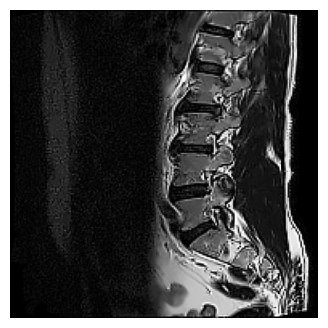

In [26]:
# Layout
tab1 = widgets.VBox([
    upload_disclaimer,
    widgets.HBox([predict_model_dropdown, upload_widget, predict_button]),
    upload_image_output,
    prediction_html,
    prob_output
])

tab2 = widgets.VBox([
    comparison_output,
    metrics_output
])

tab3 = widgets.VBox([
    widgets.HBox([viewer_model_dropdown]),
    index_slider,
    image_output
])

tab = widgets.Tab(children=[tab1, tab2, tab3])
tab.set_title(0, "Predict")
tab.set_title(1, "Comparison")
tab.set_title(2, "Image Viewer")

tab.observe(on_tab_change, names="selected_index")

display(tab)

show_comparison()
show_metrics()
show_image()
